# Helsinki (HSL) — Benchmark City for EMT Madrid Bus Electrification

**IE Sustainability Datathon 2026 · Kearney challenge: Zero-Emission Urban Bus Fleets**

This notebook computes the **GTFS-derived** File 1 indicators for **Helsinki** from the HSL source feed, so that at least one peer city is demonstrably built from source GTFS (Section 4.4 of the brief):

1. **Perimeter:** HSL bus network, whole HSL area (bus route types 701, 702, 704; tram, metro, rail and ferry excluded)
2. **Reference day:** a regular Tuesday inside the feed validity, outside public and school holidays
3. **Metrics:** bus lines, daily in-service bus-km, vehicles in service by time of day (peak), full-BEV energy at the fixed 1.30 kWh/km
4. **Output:** a partial `File_1` row. Fleet, zero-emission stock, target year, charging model and grid CO2 are **not in the timetable** and must be filled from cited sources (see last section)

Source: HSL open data, `http://dev.hsl.fi/gtfs/hsl.zip` (licence CC BY 4.0), downloaded 18 Nov 2026, feed version `2026-11-18 05:50:29`.

In [1]:
import os
import numpy as np
import pandas as pd

# ===================== INPUTS =====================
HSL_DIR = "../../hsl"            # unzipped HSL GTFS (stop_times.txt is ~1.1 GB, so it is not copied into the repo)
OUT     = "outputs"
REF, DOW = "20261124", "tuesday" # Tuesday, inside feed validity, no Finnish public holiday, regular school week
BUS_TYPES = {"701", "702", "704"}  # HSL extended route types: 701 bus, 702 express/trunk bus, 704 local bus
KWH_KM    = 1.30                 # fixed benchmark BEV factor (brief, Section 4.5)
LAYOVER_MIN = 5                  # proxy for terminus layover when block chaining is unavailable (sensitivity below)

os.makedirs(OUT, exist_ok=True)
assert pd.Timestamp(REF).day_name().lower() == DOW
rd = lambda f, **k: pd.read_csv(f"{HSL_DIR}/{f}", dtype=str, encoding="utf-8-sig", **k)

feed = rd("feed_info.txt")
print(feed.T)
assert feed.feed_start_date[0] <= REF <= feed.feed_end_date[0], "reference day outside feed validity"

                                             0
feed_publisher_name  Helsingin seudun liikenne
feed_publisher_url          http://www.hsl.fi/
feed_lang                                   fi
feed_start_date                       20261117
feed_end_date                         20270115
feed_version               2026-11-18 05:50:29


## 1. Bus network and services active on the reference day

HSL does not use GTFS `route_type` 3 for buses: it uses extended types **701 / 702 / 704**. We keep those and drop tram (0), metro (1), ferry (4), commuter rail (109) and 900. Active services follow `calendar.txt` and `calendar_dates.txt`.

In [2]:
routes = rd("routes.txt")
print(routes.route_type.value_counts().to_string())
bus_routes = routes[routes.route_type.isin(BUS_TYPES)][["route_id", "route_short_name", "route_type"]]

cal = rd("calendar.txt")
cd  = rd("calendar_dates.txt")
active  = set(cal[(cal.start_date <= REF) & (cal.end_date >= REF) & (cal[DOW] == "1")].service_id)
active |= set(cd[(cd.date == REF) & (cd.exception_type == "1")].service_id)
active -= set(cd[(cd.date == REF) & (cd.exception_type == "2")].service_id)

trips = rd("trips2.txt", usecols=["route_id", "service_id", "trip_id", "direction_id", "block_id", "shape_id"])
bt = trips[trips.service_id.isin(active)].merge(bus_routes, on="route_id")
print(f"active services: {len(active)} | bus trips on {REF}: {len(bt):,} | bus routes: {bt.route_id.nunique()}")
print("block_id coverage on active bus trips:", f"{bt.block_id.notna().mean():.1%}")

route_type
701    347
704     46
0       32
702     14
109     13
1        4
4        3
900      1
active services: 509 | bus trips on 20261124: 19,286 | bus routes: 390
block_id coverage on active bus trips: 0.0%


## 2. Trip start, end and length from `stop_times.txt`

`stop_times.txt` is read in chunks and reduced to one row per bus trip: first departure, last arrival and distance travelled (`shape_dist_traveled`, in km in this feed). Times beyond 24:00 are kept (post-midnight trips of the same service day).

In [3]:
def to_min(s):
    p = s.str.split(":", expand=True).astype(int)
    return p[0] * 60 + p[1] + p[2] / 60

ids = set(bt.trip_id)
agg = []
cols = ["trip_id", "departure_time", "arrival_time", "shape_dist_traveled"]
for ch in pd.read_csv(f"{HSL_DIR}/stop_times.txt", usecols=cols, dtype=str, encoding="utf-8-sig", chunksize=3_000_000):
    ch = ch[ch.trip_id.isin(ids)]
    if ch.empty:
        continue
    ch = ch.assign(dep=to_min(ch.departure_time), arr=to_min(ch.arrival_time), dist=ch.shape_dist_traveled.astype(float))
    agg.append(ch.groupby("trip_id").agg(start=("dep", "min"), end=("arr", "max"), d0=("dist", "min"), d1=("dist", "max")))
st = pd.concat(agg).groupby(level=0).agg(start=("start", "min"), end=("end", "max"), d0=("d0", "min"), d1=("d1", "max"))
st["km"] = st.d1 - st.d0

tt = bt.merge(st, left_on="trip_id", right_index=True, how="left")
print("trips without stop_times:", tt.km.isna().sum(), "| trips with km <= 0:", (tt.km <= 0).sum())
tt = tt[tt.km > 0].copy()
print(f"{len(tt):,} bus trips, median length {tt.km.median():.1f} km, max {tt.km.max():.1f} km")

trips without stop_times: 0 | trips with km <= 0: 0
19,286 bus trips, median length 14.8 km, max 60.6 km


### Distance check against shape geometry

The distances are checked on a random sample of trips against the haversine length of each trip's shape (geodesic method, as the brief requires).

In [4]:
def hav(lat1, lon1, lat2, lon2):
    p = np.pi / 180
    a = np.sin((lat2 - lat1) * p / 2) ** 2 + np.cos(lat1 * p) * np.cos(lat2 * p) * np.sin((lon2 - lon1) * p / 2) ** 2
    return 12742 * np.arcsin(np.sqrt(a))

samp = tt.sample(300, random_state=1)
shp = rd("shapes.txt", usecols=["shape_id", "shape_pt_lat", "shape_pt_lon", "shape_pt_sequence"])
shp = shp[shp.shape_id.isin(set(samp.shape_id))].copy()
for c in ["shape_pt_lat", "shape_pt_lon", "shape_pt_sequence"]:
    shp[c] = shp[c].astype(float)
shp = shp.sort_values(["shape_id", "shape_pt_sequence"])
lat, lon = shp.shape_pt_lat.values, shp.shape_pt_lon.values
seg = np.r_[0, hav(lat[:-1], lon[:-1], lat[1:], lon[1:])]
seg[(shp.shape_id != shp.shape_id.shift()).values] = 0
shape_km = pd.Series(seg, index=shp.index).groupby(shp.shape_id).sum()
chk = samp.assign(shape_km=samp.shape_id.map(shape_km))
ratio = (chk.km / chk.shape_km).dropna()
print(f"stop_times km / shape km: median {ratio.median():.3f}, 5th-95th pct {ratio.quantile(.05):.3f}-{ratio.quantile(.95):.3f}")

stop_times km / shape km: median 1.002, 5th-95th pct 1.000-1.012


## 3. Line metrics and daily bus-km

In [5]:
lines = (tt.groupby("route_short_name")
           .agg(route_type=("route_type", "first"), trips=("trip_id", "count"), daily_km=("km", "sum"),
                first_dep_min=("start", "min"), last_arr_min=("end", "max"))
           .sort_values("daily_km", ascending=False).reset_index())
lines["service_hours"] = (lines.last_arr_min - lines.first_dep_min) / 60
n_bus_lines = lines.route_short_name.nunique()
daily_bus_km = tt.km.sum()
print(f"bus lines: {n_bus_lines} | trips: {len(tt):,} | daily in-service bus-km: {daily_bus_km:,.0f}")
print(lines.groupby("route_type").agg(lines=("route_short_name", "count"), km=("daily_km", "sum")).round(0))
lines.head(10)

bus lines: 390 | trips: 19,286 | daily in-service bus-km: 289,735
            lines        km
route_type                 
701           331  227951.0
702            14   57386.0
704            45    4397.0


,route_short_name,route_type,trips,daily_km,first_dep_min,last_arr_min,service_hours
0,560,702,230,6442.472,246.0,1583.0,22.283333
1,510,702,221,6305.212,287.0,1540.0,20.883333
2,520,702,218,5691.326,274.0,1514.0,20.666667
3,600,702,255,5321.343,250.0,1711.0,24.350000
4,530,702,204,5091.872,270.0,1497.0,20.450000
5,570,702,216,4724.567,238.0,1482.0,20.733333
6,200,702,195,4569.981,283.0,1472.0,19.816667
7,300,702,208,3717.536,301.0,1533.0,20.533333
8,400,702,202,3653.877,281.0,1457.0,19.600000
9,59,701,216,3623.354,288.0,1454.0,19.433333


## 4. Vehicles in service by time of day

None of the active bus trips carries a `block_id` in this feed (the few populated values belong to tram and metro), so a vehicle's chain of trips cannot be rebuilt as in the Brussels notebook. We therefore count **concurrent trips** minute by minute and add a **terminus layover** of `LAYOVER_MIN` minutes after each trip. This is a **proxy and a lower bound** for peak vehicles (it ignores longer layovers and deadheading), to be flagged in the report annex.

In [6]:
def curve(layover):
    n = int(tt.end.max() + layover) + 3
    d = np.zeros(n + 1)
    np.add.at(d, np.floor(tt.start.values).astype(int), 1)
    np.add.at(d, np.ceil(tt.end.values + layover).astype(int), -1)
    return np.cumsum(d)[:n]

vc = pd.DataFrame({"minute": np.arange(len(curve(0))), "in_motion": curve(0)})
vc["with_layover"] = curve(LAYOVER_MIN)[: len(vc)]
pk0, pk1 = vc.in_motion.max(), vc.with_layover.max()
t = lambda m: f"{int(m // 60):02d}:{int(m % 60):02d}"
print(f"peak trips in motion: {pk0:.0f} at {t(vc.in_motion.idxmax())}")
print(f"peak vehicles incl. {LAYOVER_MIN}-min layover: {pk1:.0f} at {t(vc.with_layover.idxmax())}")
print(f"mean km per peak vehicle: {daily_bus_km / pk1:.0f} km/day")

peak trips in motion: 934 at 08:08
peak vehicles incl. 5-min layover: 1041 at 08:12
mean km per peak vehicle: 278 km/day


## 5. Energy and File 1 row (GTFS-derived part)

`energy_full_bev_mwh_day = daily_bus_km * 1.30 / 1000`. Fields that cannot come from the timetable are left **empty (not zero)** until sourced.

In [7]:
file1 = pd.DataFrame([{
    "city": "Helsinki",
    "operator": "HSL Helsinki Region Transport (bus network, whole HSL area)",
    "reference_date": pd.Timestamp(REF).strftime("%Y-%m-%d"),
    "n_bus_lines": n_bus_lines,
    "daily_bus_km": round(daily_bus_km, 1),
    "fleet_total": np.nan, "ze_fleet": np.nan, "ze_share_pct": np.nan, "fleet_data_year": np.nan,
    "ze_target_year": np.nan, "charging_model": "",
    "energy_full_bev_mwh_day": round(daily_bus_km * KWH_KM / 1000, 1),
    "grid_co2_g_kwh": np.nan,
    "source_urls": "http://dev.hsl.fi/gtfs/hsl.zip (HSL GTFS, downloaded 2026-11-18, feed version 2026-11-18 05:50:29)",
}])
lines.to_csv(f"{OUT}/helsinki_bus_lines.csv", index=False)
vc.to_csv(f"{OUT}/helsinki_vehicles_by_minute.csv", index=False)
file1.to_csv(f"{OUT}/helsinki_file1_partial.csv", index=False)
print(file1.T)

                                                                         0
city                                                              Helsinki
operator                 HSL Helsinki Region Transport (bus network, wh...
reference_date                                                  2026-11-24
n_bus_lines                                                            390
daily_bus_km                                                      289734.6
fleet_total                                                            NaN
ze_fleet                                                               NaN
ze_share_pct                                                           NaN
fleet_data_year                                                        NaN
ze_target_year                                                         NaN
charging_model                                                            
energy_full_bev_mwh_day                                              376.7
grid_co2_g_kwh           

## 5b. Sourced (non-GTFS) File 1 fields

Fleet, zero-emission stock, target year, charging model and grid CO2 are not in the timetable. They are filled here from cited sources, each tagged **V** verified, **D** derived, **P** proxy, **A** assumption (same convention as the Madrid model).

* **`ze_fleet` / `ze_share_pct`**: HSL table "Electric buses on the services we procure", 2025: 600 buses, 52% of buses. The text on the same page says "approximately 650"; 600 is used because it pairs with the 52% share.
* **`fleet_total`**: HSL does not publish a vehicle count on its web pages, so it is **derived** as 600 / 0.52. The check below compares it with the GTFS peak. Replace with the HSL *Annual and Responsibility Report 2025* figure when available.
* **`ze_target_year`**: HSL: "public transport in the Helsinki region to be completely emission-free by 2035". This covers all public transport, not only buses.
* **`grid_co2_g_kwh`**: national **production-based** average, the same method as Madrid (Red Eléctrica). Electricity Maps 2025 is used as a proxy until Statistics Finland table 14qt publishes 2025. HSL's "Nordic wind and hydro" contract claim (~0 g) is not used, because it is not comparable with Madrid.

In [8]:
# ===== Sourced (non-GTFS) File 1 fields =====
HSL_EBUS = "https://www.hsl.fi/en/hsl/electric-buses"
SOURCED = {
    "ze_fleet":        (600,  "V", HSL_EBUS + " (table, 2025; page text says ~650)"),
    "ze_share_pct":    (52.0, "V", HSL_EBUS + " (share of buses on procured services, 2025)"),
    "fleet_data_year": (2025, "V", HSL_EBUS),
    "fleet_total":     (round(600 / 0.52), "D", "derived = ze_fleet / ze_share; replace with HSL Annual and Responsibility Report 2025"),
    "ze_target_year":  (2035, "V", HSL_EBUS + " ('public transport ... completely emission-free by 2035'; all modes)"),
    "charging_model":  ("Depot (overnight + daytime breaks) + terminus opportunity charging on some routes", "V", HSL_EBUS),
    "grid_co2_g_kwh":  (72.8, "P", "https://www.electricitymaps.com/grid-in-review-2025/finland (2025, production-based); "
                                   "replace with Statistics Finland table 14qt"),
}
for k, (v, cls, src) in SOURCED.items():
    file1[k] = v
urls = ["https://www.hsl.fi/en/hsl/electric-buses",
        "https://www.electricitymaps.com/grid-in-review-2025/finland"]
file1["source_urls"] = file1.source_urls + " | " + " | ".join(urls)
file1.to_csv(f"{OUT}/helsinki_file1.csv", index=False)

register = pd.DataFrame(SOURCED, index=["value", "class", "source"]).T
register.to_csv(f"{OUT}/helsinki_sourced_fields.csv")

# sanity check: fleet / GTFS peak (lower-bound proxy) should be roughly 1.15-1.4 (Brussels 850 / 616 = 1.38)
spare = file1.fleet_total[0] / pk1
print(f"fleet_total {file1.fleet_total[0]} / GTFS peak incl. layover {pk1:.0f} = {spare:.2f}",
      "-> plausible" if 1.1 <= spare <= 1.5 else "-> CHECK: derived fleet_total looks inconsistent with the timetable")
print(f"ZE share check: {file1.ze_fleet[0]} / {file1.fleet_total[0]} = {100 * file1.ze_fleet[0] / file1.fleet_total[0]:.1f}%")
print(file1.T)
register

fleet_total 1154 / GTFS peak incl. layover 1041 = 1.11 -> plausible
ZE share check: 600 / 1154 = 52.0%
                                                                         0
city                                                              Helsinki
operator                 HSL Helsinki Region Transport (bus network, wh...
reference_date                                                  2026-11-24
n_bus_lines                                                            390
daily_bus_km                                                      289734.6
fleet_total                                                           1154
ze_fleet                                                               600
ze_share_pct                                                          52.0
fleet_data_year                                                       2025
ze_target_year                                                        2035
charging_model           Depot (overnight + daytime breaks) + terminus .

,value,class,source
ze_fleet,600,V,https://www.hsl.fi/en/hsl/electric-buses (tabl...
ze_share_pct,52.0,V,https://www.hsl.fi/en/hsl/electric-buses (shar...
fleet_data_year,2025,V,https://www.hsl.fi/en/hsl/electric-buses
fleet_total,1154,D,derived = ze_fleet / ze_share; replace with HS...
ze_target_year,2035,V,https://www.hsl.fi/en/hsl/electric-buses ('pub...
charging_model,Depot (overnight + daytime breaks) + terminus ...,V,https://www.hsl.fi/en/hsl/electric-buses
grid_co2_g_kwh,72.8,P,https://www.electricitymaps.com/grid-in-review...


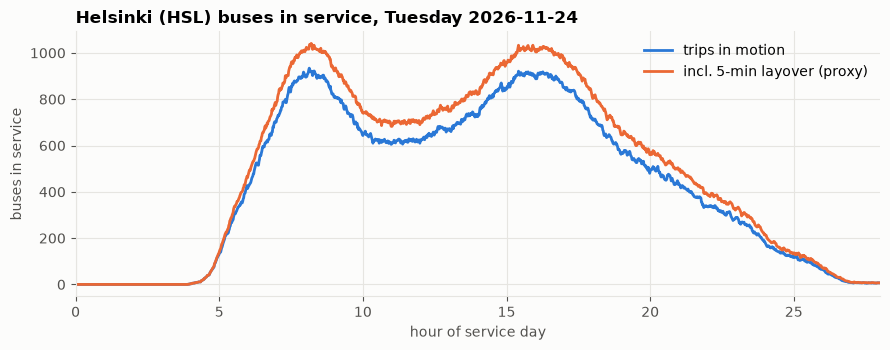

In [9]:
import matplotlib.pyplot as plt

# Chart style shared with the Brussels and Madrid notebooks (validated palette: slot 1 blue, slot 2 orange, slot 3 aqua)
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "font.size": 10, "legend.frameon": False,
})
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(vc.minute / 60, vc.in_motion, label="trips in motion", lw=2, color=C1)
ax.plot(vc.minute / 60, vc.with_layover, label=f"incl. {LAYOVER_MIN}-min layover (proxy)", lw=2, color=C2)
ax.set_xlim(0, 28); ax.set_xlabel("hour of service day"); ax.set_ylabel("buses in service")
ax.set_title(f"Helsinki (HSL) buses in service, Tuesday {pd.Timestamp(REF).date()}")
ax.legend(frameon=False); fig.tight_layout()
fig.savefig(f"{OUT}/fig_helsinki_vehicles_by_hour.png", dpi=160)
plt.show()

## 7. Route and network graphs

### 7a. Route-level vehicles, km per bus and energy

The Madrid model's route test applied to Helsinki. With no `block_id`, each line's vehicles are its **peak concurrent trips plus the 5-minute layover** (same proxy as Section 4, per line). It is a lower bound, so km per bus and energy per bus are **upper bounds**, which makes the charging test conservative.

Rule (Madrid model, brief rule 2): **Depot** if km per bus ≤ 300 km (standard) or 240 km (articulated); **Opportunity** up to 2× that; otherwise **Not_feasible**. Base case: every bus is standard (1.30 kWh/km), as fixed by the brief for benchmarks. Sensitivity: trunk lines (route type 702) run 18 m articulated buses (1.85 kWh/km, 240 km).

In [10]:
# ===================== INPUTS =====================
RANGE_KM  = {"Standard": 300, "Articulated": 240}     # Madrid model / brief Section 4.5
KWH_TYPE  = {"Standard": 1.30, "Articulated": 1.85}
OPP_MAX   = 2.0                                       # Opportunity accepted up to 2x the range (Madrid team assumption)
TYPE_NAME = {"701": "Regular", "702": "Trunk", "704": "Local"}
TYPE_COL  = {"Regular": C1, "Trunk": C2, "Local": C3}  # fixed categorical order
# ==================================================

def line_peak(g, layover=LAYOVER_MIN):
    n = int(g.end.max() + layover) + 3
    d = np.zeros(n + 1)
    np.add.at(d, np.floor(g.start.values).astype(int), 1)
    np.add.at(d, np.ceil(g.end.values + layover).astype(int), -1)
    return int(np.cumsum(d).max())

r = lines.set_index("route_short_name").copy()
r["vehicles"] = tt.groupby("route_short_name")[["start", "end"]].apply(line_peak)
r["kind"] = r.route_type.map(TYPE_NAME)
r["km_per_bus_day"] = r.daily_km / r.vehicles

def charging(df, trunk_articulated):
    bus_type = pd.Series(np.where(trunk_articulated & (df.route_type == "702"), "Articulated", "Standard"), index=df.index)
    lim = bus_type.map(RANGE_KM)
    strat = np.select([df.km_per_bus_day <= lim, df.km_per_bus_day <= OPP_MAX * lim], ["Depot", "Opportunity"], "Not_feasible")
    return bus_type, df.km_per_bus_day * bus_type.map(KWH_TYPE), pd.Series(strat, index=df.index)

r["bus_type"], r["energy_kwh_bus_day"], r["charging_strategy"] = charging(r, False)
_, r["energy_kwh_bus_day_art"], r["charging_strategy_art"] = charging(r, True)
r = r.sort_values("energy_kwh_bus_day", ascending=False)

print(f"sum of line peaks {r.vehicles.sum():,} vs network peak {pk1:.0f} "
      f"(lines peak at different times, so the sum is higher)")
print(f"km per bus per day: median {r.km_per_bus_day.median():.0f} | 90th pct {r.km_per_bus_day.quantile(.9):.0f} | max {r.km_per_bus_day.max():.0f}")
print("\nBase (all standard):", r.charging_strategy.value_counts().to_dict())
print("Sensitivity (trunk = articulated):", r.charging_strategy_art.value_counts().to_dict())
OPP_LINES = r.index[r.charging_strategy != "Depot"].tolist()
OPP_LINES_ART = r.index[r.charging_strategy_art != "Depot"].tolist()
print("Lines above depot range, base:", OPP_LINES)
print("Lines above depot range, trunk articulated:", OPP_LINES_ART)
print("\nBy route type:")
print(r.groupby("kind").agg(lines=("trips", "size"), daily_km=("daily_km", "sum"), vehicles=("vehicles", "sum"),
                            median_km_per_bus=("km_per_bus_day", "median")).round(0))
# robustness: the 5-min layover undercounts vehicles, so test longer layovers
lay = {}
for L in [5, 10, 15]:
    v = tt.groupby("route_short_name")[["start", "end"]].apply(line_peak, layover=L)
    kpb = r.daily_km / v.reindex(r.index)
    lay[f"{L} min"] = {"lines > 300 km/bus": int((kpb > RANGE_KM["Standard"]).sum()),
                       "trunk lines > 300 km/bus": int((kpb[r.route_type == "702"] > 300).sum()),
                       "median km/bus": round(kpb.median()),
                       "network peak": int(curve(L).max())}
    if L == 15:
        ROBUST_OPP = kpb[kpb > RANGE_KM["Standard"]].sort_values(ascending=False)
LAYOVER_SENS = pd.DataFrame(lay)
print("\nLayover sensitivity:"); print(LAYOVER_SENS.to_string())
print("Still above 300 km/bus with a 15-min layover:", ROBUST_OPP.round(0).to_dict())
r.to_csv(f"{OUT}/helsinki_route_energy.csv")
r[["kind", "trips", "daily_km", "vehicles", "km_per_bus_day", "energy_kwh_bus_day",
   "charging_strategy", "charging_strategy_art"]].head(15).round(1)

sum of line peaks 1,534 vs network peak 1041 (lines peak at different times, so the sum is higher)
km per bus per day: median 118 | 90th pct 265 | max 549

Base (all standard): {'Depot': 365, 'Opportunity': 25}
Sensitivity (trunk = articulated): {'Depot': 362, 'Opportunity': 28}
Lines above depot range, base: ['841', '842', '731', '739', '711', '530', '717', '560', '520', '553', '544', '173Z', '561', '562', '721', '570', '600', '531', '171', '971', '844', '400', '247', '584', '510']
Lines above depot range, trunk articulated: ['841', '842', '731', '739', '711', '530', '717', '560', '520', '553', '544', '173Z', '561', '562', '721', '570', '600', '531', '171', '971', '844', '400', '247', '584', '510', '300', '200', '40']

By route type:
         lines  daily_km  vehicles  median_km_per_bus
kind                                                 
Local       45    4397.0        70               57.0
Regular    331  227951.0      1262              123.0
Trunk       14   57386.0       202     

,kind,trips,daily_km,vehicles,km_per_bus_day,energy_kwh_bus_day,charging_strategy,charging_strategy_art
route_short_name,,,,,,,,
841,Regular,36,1098.7,2,549.3,714.1,Opportunity,Opportunity
842,Regular,35,814.9,2,407.5,529.7,Opportunity,Opportunity
731,Regular,93,2829.9,7,404.3,525.6,Opportunity,Opportunity
739,Regular,54,1849.9,5,370.0,481.0,Opportunity,Opportunity
711,Regular,92,1819.1,5,363.8,473.0,Opportunity,Opportunity
530,Trunk,204,5091.9,14,363.7,472.8,Opportunity,Opportunity
717,Regular,110,2879.0,8,359.9,467.8,Opportunity,Opportunity
560,Trunk,230,6442.5,18,357.9,465.3,Opportunity,Opportunity
520,Trunk,218,5691.3,16,355.7,462.4,Opportunity,Opportunity


### 7b. Network maps

One representative shape per bus line (its most-used shape on the reference day). Tram, metro and commuter rail are drawn in light grey for context. Depot locations are not plotted: HSL buses are run by contracted operators, and their depots are not in the GTFS feed.

bus lines with geometry: 390 of 390 | rail shapes: 228


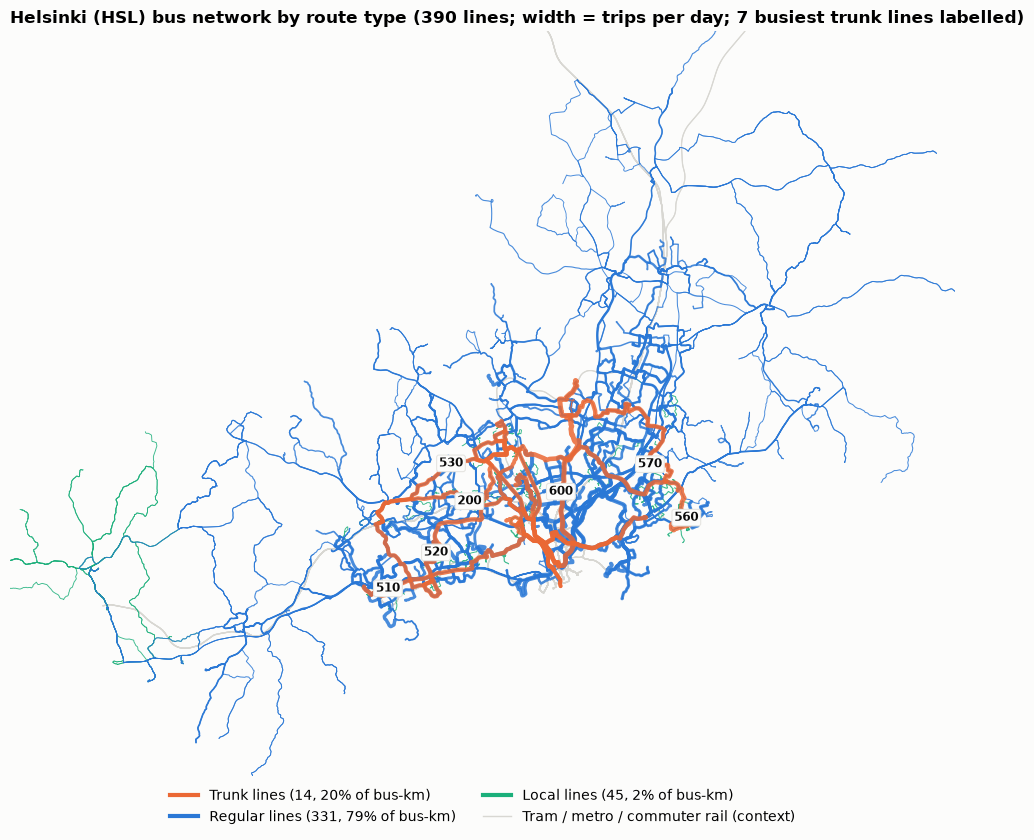

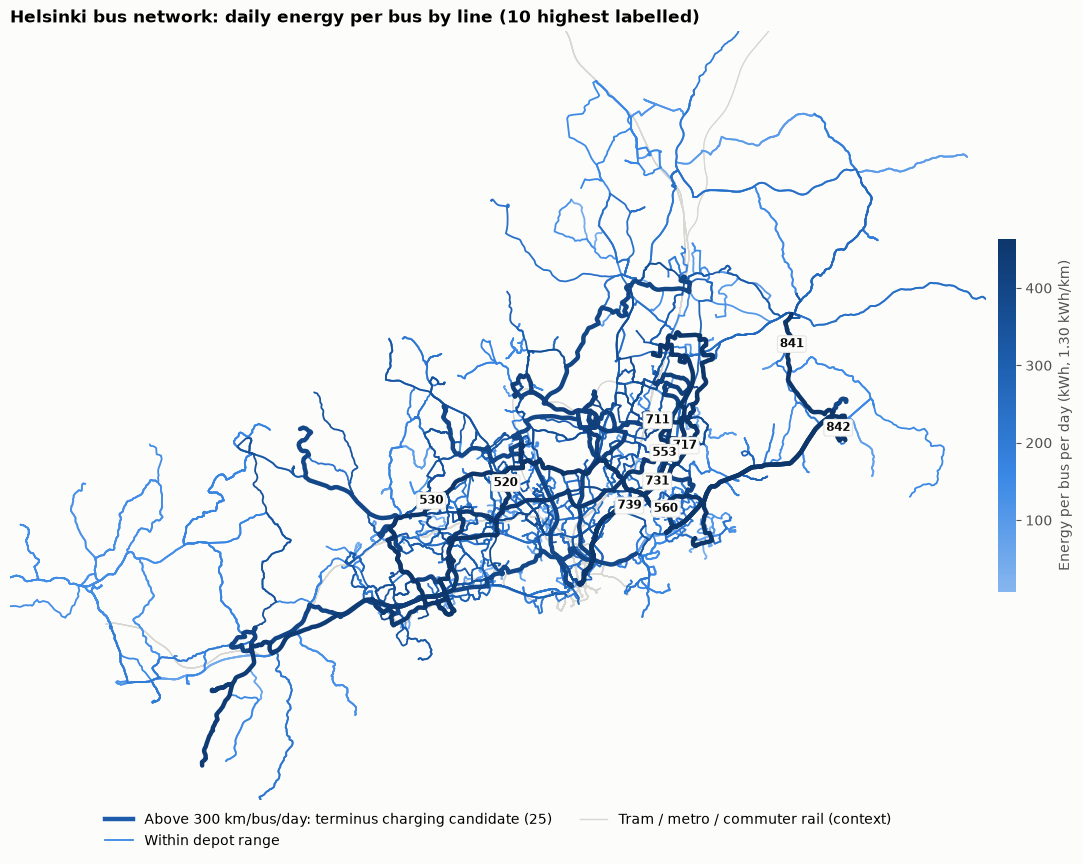

In [11]:
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.lines import Line2D

rep = tt.groupby("route_short_name").shape_id.agg(lambda x: x.value_counts().index[0])
rail = trips.merge(routes[["route_id", "route_type"]], on="route_id")
rail_ids = set(rail[rail.route_type.isin(["0", "1", "109"])].shape_id.dropna())
need = set(rep) | rail_ids
geo_all = rd("shapes.txt", usecols=["shape_id", "shape_pt_lat", "shape_pt_lon", "shape_pt_sequence"])
geo_all = geo_all[geo_all.shape_id.isin(need)].astype({"shape_pt_lat": float, "shape_pt_lon": float, "shape_pt_sequence": int})
geo = {k: g.sort_values("shape_pt_sequence") for k, g in geo_all.groupby("shape_id")}
print(f"bus lines with geometry: {sum(s in geo for s in rep)} of {len(rep)} | rail shapes: {sum(s in geo for s in rail_ids)}")

bus_pts = pd.concat([geo[s] for s in set(rep)])
BX = bus_pts.shape_pt_lon.quantile([0.002, 0.998]).values
BY = bus_pts.shape_pt_lat.quantile([0.002, 0.998]).values

def base_map(figsize=(12, 8.5)):
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_aspect(1 / np.cos(np.radians(60.2)))
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.set_xlim(BX[0] - 0.02, BX[1] + 0.02); ax.set_ylim(BY[0] - 0.01, BY[1] + 0.01)   # crop to the bus network
    for sid in rail_ids:
        if sid in geo:
            ax.plot(geo[sid].shape_pt_lon, geo[sid].shape_pt_lat, color="#d8d7d2", lw=0.8, zorder=1)
    return fig, ax

def label(ax, line, pos=0.55):
    g = geo[rep[line]]; p = g.iloc[int(len(g) * pos)]
    ax.annotate(line, (p.shape_pt_lon, p.shape_pt_lat), fontsize=8.5, fontweight="bold", color=INK, ha="center",
                va="center", zorder=6, bbox=dict(boxstyle="round,pad=0.2", fc="#fcfcfb", ec=GRID, lw=0.8))

# ---- Map 1: network structure: route type, line width = trips per day ----
fig, ax = base_map()
w = lambda n: 0.6 + 3.0 * n / r.trips.max()
for kind in ["Local", "Regular", "Trunk"]:                      # trunk drawn on top
    for line, row in r[r.kind == kind].iterrows():
        g = geo[rep[line]]
        ax.plot(g.shape_pt_lon, g.shape_pt_lat, color=TYPE_COL[kind], lw=w(row.trips), alpha=0.85,
                zorder=3 if kind == "Trunk" else 2, solid_capstyle="round")
for k, line in enumerate(r[r.kind == "Trunk"].sort_values("daily_km", ascending=False).index[:7]):
    label(ax, line, pos=[0.15, 0.85, 0.3, 0.7, 0.2, 0.8, 0.5][k])
ax.legend(handles=[Line2D([], [], color=TYPE_COL[k], lw=3, label=f"{k} lines ({(r.kind == k).sum()}, "
                          f"{100 * r.loc[r.kind == k, 'daily_km'].sum() / r.daily_km.sum():.0f}% of bus-km)")
                   for k in ["Trunk", "Regular", "Local"]]
               + [Line2D([], [], color="#d8d7d2", lw=1, label="Tram / metro / commuter rail (context)")],
          loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2)
ax.set_title(f"Helsinki (HSL) bus network by route type ({len(r)} lines; width = trips per day; 7 busiest trunk lines labelled)")
fig.tight_layout(); fig.savefig(f"{OUT}/fig_helsinki_network_by_type.png", dpi=160); plt.show()

# ---- Map 2: energy per bus per day, thick = above standard depot range ----
cmap = LinearSegmentedColormap.from_list("blue_seq", ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
vmax = float(r.energy_kwh_bus_day.quantile(0.98))
norm = Normalize(vmin=r.energy_kwh_bus_day.min(), vmax=vmax)
fig, ax = base_map()
for line, row in r.sort_values("energy_kwh_bus_day").iterrows():
    g = geo[rep[line]]; hot = line in OPP_LINES
    ax.plot(g.shape_pt_lon, g.shape_pt_lat, color=cmap(norm(min(row.energy_kwh_bus_day, vmax))),
            lw=3.2 if hot else 1.3, zorder=3 if hot else 2, solid_capstyle="round")
for k, line in enumerate((OPP_LINES or r.index[:6].tolist())[:10]):
    label(ax, line, pos=[0.85, 0.15, 0.7, 0.3, 0.9, 0.35, 0.6, 0.4, 0.8, 0.2][k])
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
cb = fig.colorbar(sm, ax=ax, shrink=0.45, pad=0.01)
cb.set_label("Energy per bus per day (kWh, 1.30 kWh/km)", color=INK2); cb.outline.set_visible(False)
ax.legend(handles=[Line2D([], [], color="#1c5cab", lw=3.2, label=f"Above 300 km/bus/day: terminus charging candidate ({len(OPP_LINES)})"),
                   Line2D([], [], color="#3987e5", lw=1.3, label="Within depot range"),
                   Line2D([], [], color="#d8d7d2", lw=1, label="Tram / metro / commuter rail (context)")],
          loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2)
ax.set_title("Helsinki bus network: daily energy per bus by line (10 highest labelled)")
fig.tight_layout(); fig.savefig(f"{OUT}/fig_helsinki_network_energy_map.png", dpi=160); plt.show()

### 7c. Route charts: where the bus-km are, and which routes stretch a battery

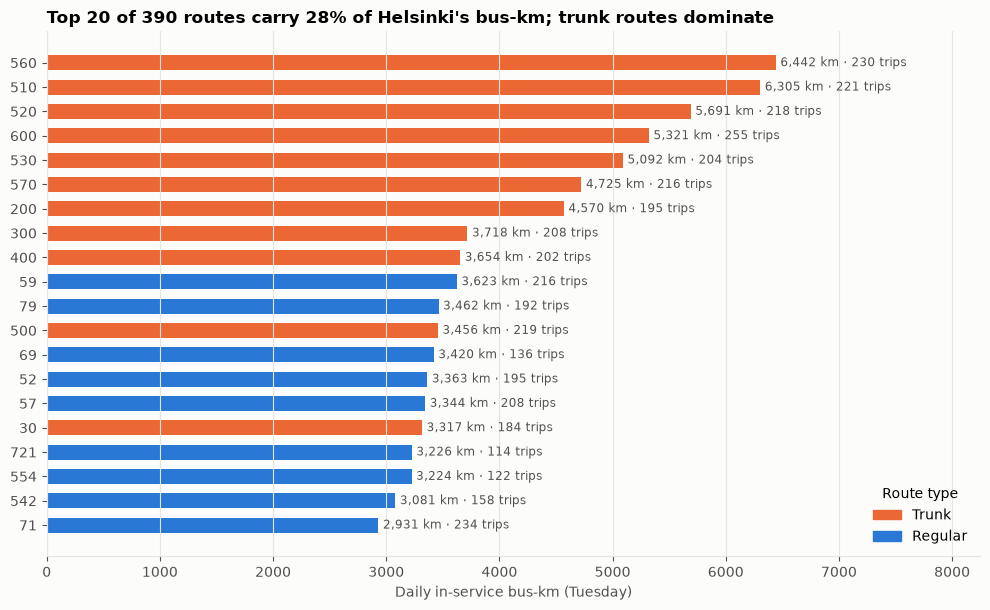

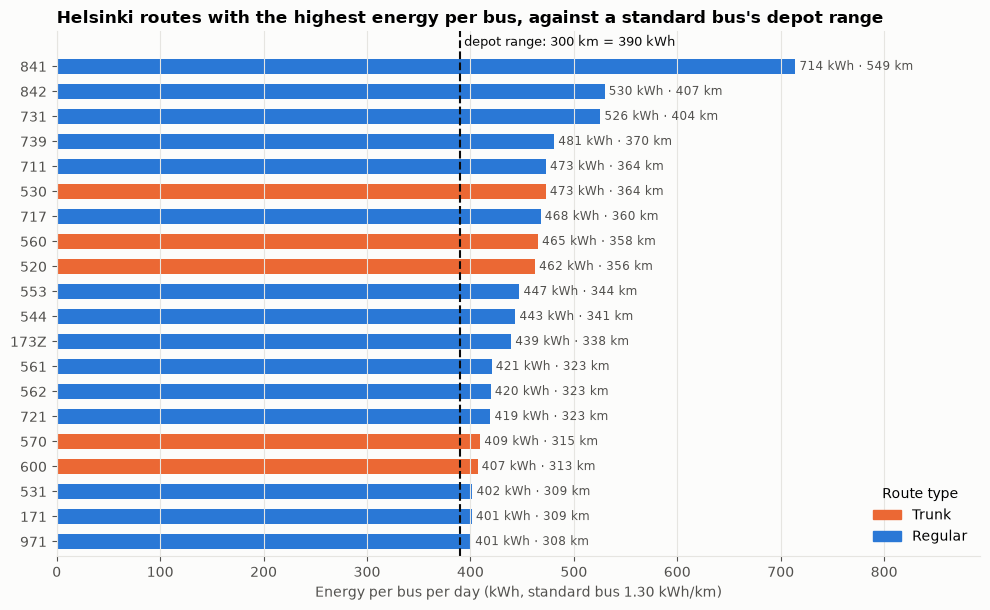

In [12]:
from matplotlib.patches import Patch
legend_for = lambda d: [Patch(color=TYPE_COL[k], label=k) for k in ["Trunk", "Regular", "Local"] if (d.kind == k).any()]

# ---- busiest routes by daily bus-km ----
top = r.sort_values("daily_km", ascending=False).head(20)
share_top20 = 100 * top.daily_km.sum() / r.daily_km.sum()
top = top.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6.2))
ax.barh(top.index, top.daily_km, color=top.kind.map(TYPE_COL), height=0.62)
for y, (v, n) in enumerate(zip(top.daily_km, top.trips)):
    ax.text(v + 40, y, f"{v:,.0f} km · {n} trips", va="center", fontsize=8.5, color=INK2)
ax.set_xlim(0, top.daily_km.max() * 1.28); ax.grid(axis="y", visible=False)
ax.set_xlabel("Daily in-service bus-km (Tuesday)")
ax.set_title(f"Top 20 of {len(r)} routes carry {share_top20:.0f}% of Helsinki's bus-km; trunk routes dominate")
ax.legend(handles=legend_for(top), loc="lower right", title="Route type")
fig.tight_layout(); fig.savefig(f"{OUT}/fig_helsinki_top_routes_km.png", dpi=160); plt.show()

# ---- energy per bus per day vs the standard depot range ----
LIM_KWH = RANGE_KM["Standard"] * KWH_TYPE["Standard"]
top = r.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6.2))
ax.barh(top.index, top.energy_kwh_bus_day, color=top.kind.map(TYPE_COL), height=0.62)
for y, (v, k) in enumerate(zip(top.energy_kwh_bus_day, top.km_per_bus_day)):
    ax.text(v + 4, y, f"{v:.0f} kWh · {k:.0f} km", va="center", fontsize=8.5, color=INK2)
ax.axvline(LIM_KWH, color=INK, lw=1.5, ls="--")
ax.text(LIM_KWH, len(top) - 0.3, f" depot range: 300 km = {LIM_KWH:.0f} kWh", color=INK, fontsize=9, va="bottom")
ax.set_xlim(0, max(top.energy_kwh_bus_day.max(), LIM_KWH) * 1.25); ax.set_ylim(-0.6, len(top) + 0.4)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Energy per bus per day (kWh, standard bus 1.30 kWh/km)")
ax.set_title("Helsinki routes with the highest energy per bus, against a standard bus's depot range")
ax.legend(handles=legend_for(top), loc="lower right", title="Route type")
fig.tight_layout(); fig.savefig(f"{OUT}/fig_helsinki_energy_per_bus_by_route.png", dpi=160); plt.show()

### 7d. Network comparison with Madrid and Brussels

Vehicles in service by time of day, indexed to each city's own peak. Madrid and Brussels come from `../Brussels/outputs/vehicles_in_service_by_minute.csv` (GTFS blocks, layovers included). Helsinki uses the trip + 5-minute-layover proxy, so its midday share may be slightly understated relative to the other two.

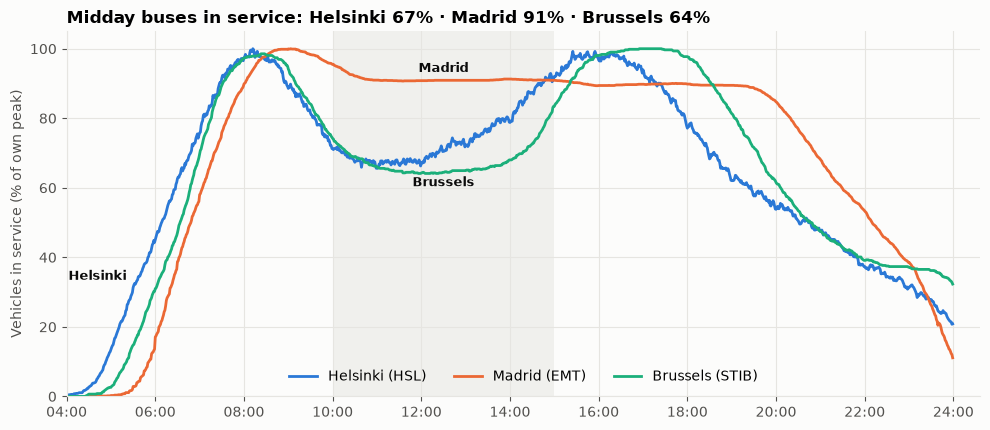

Helsinki peak vehicles = trip + 5-min layover proxy (lower bound); Madrid/Brussels = GTFS blocks.
Fleet: Madrid 31 Dec 2025 (Madrid model); Brussels 2026 (STIB, ~143 BEB of 850); Helsinki 2025 (derived total, Section 5b).


,Madrid (EMT),Brussels (STIB),Helsinki (HSL),Helsinki / Madrid
Bus lines (weekday),234.0,51.0,390.0,1.67
Daily bus-km,339331.0,91639.0,289735.0,0.85
Peak vehicles in service (GTFS blocks),1937.0,616.0,1041.0,0.54
"Peak vehicles (EMT supply file, NumCCReal)",2042.0,NaN,NaN,NaN
km per peak vehicle per day (blocks),175.2,148.8,278.3,1.59
Midday vehicles as % of peak,90.8,64.3,67.0,0.74
100% BEB energy (MWh/day),447.2,133.4,376.7,0.84
Lines needing opportunity charging,6.0,4.0,25.0,4.17
Fleet total,2210.0,850.0,1154.0,0.52
Zero-emission share of fleet (%),20.9,16.8,52.0,2.49


In [13]:
prof = pd.read_csv("../Brussels/outputs/vehicles_in_service_by_minute.csv")
hel = vc.with_layover.values[: 24 * 60]
series = [("Helsinki (HSL)", hel, C1), ("Madrid (EMT)", prof.madrid.values, C2), ("Brussels (STIB)", prof.brussels.values, C3)]
hours = np.arange(24 * 60) / 60

fig, ax = plt.subplots(figsize=(10, 4.4))
for name, cur, col in series:
    pct = 100 * cur / cur.max()
    ax.plot(hours, pct, color=col, lw=2, label=name)
    hx, dy = {"Helsinki (HSL)": (5.6, 0), "Madrid (EMT)": (12.5, 6), "Brussels (STIB)": (12.5, -10)}[name]
    ax.annotate(name.split(" ")[0], (hx, pct[int(hx * 60)]), xytext=(-8 if name.startswith("Hel") else 0, dy), textcoords="offset points",
                color=INK, fontsize=9, ha="right" if name.startswith("Hel") else "center", fontweight="bold")
ax.axvspan(10, 15, color=GRID, alpha=0.5, lw=0)
ax.set_xlim(4, 24.6); ax.set_ylim(0, 105); ax.set_xticks(range(4, 25, 2))
ax.set_xticklabels([f"{h:02d}:00" for h in range(4, 25, 2)])
ax.set_ylabel("Vehicles in service (% of own peak)")
mid = {n: 100 * c[12 * 60] / c.max() for n, c, _ in series}
ax.set_title("Midday buses in service: " + " · ".join(f"{n.split(' ')[0]} {v:.0f}%" for n, v in mid.items()))
ax.legend(loc="lower center", ncol=3)
fig.tight_layout(); fig.savefig(f"{OUT}/fig_helsinki_vs_madrid_brussels_by_hour.png", dpi=160); plt.show()

# ---- three-city benchmark table ----
bench = pd.read_csv("../Brussels/outputs/benchmark_madrid_vs_brussels.csv", index_col=0)[["Madrid (EMT)", "Brussels (STIB)"]]
bench.loc["Peak vehicles in service (GTFS blocks)", "Helsinki (HSL)"] = np.nan
bench["Helsinki (HSL)"] = pd.Series({
    "Bus lines (weekday)": len(r),
    "Daily bus-km": round(daily_bus_km),
    "Peak vehicles in service (GTFS blocks)": round(pk1),          # Helsinki: trip + layover proxy, not blocks
    "km per peak vehicle per day (blocks)": round(daily_bus_km / pk1, 1),
    "Midday vehicles as % of peak": round(mid["Helsinki (HSL)"], 1),
    "100% BEB energy (MWh/day)": round(daily_bus_km * KWH_KM / 1000, 1),
    "Lines needing opportunity charging": len(OPP_LINES),
})
bench.loc["Fleet total"] = [2210, 850, file1.fleet_total[0]]
bench.loc["Zero-emission share of fleet (%)"] = [round(100 * (452 + 10) / 2210, 1), round(100 * 143 / 850, 1), file1.ze_share_pct[0]]
bench["Helsinki / Madrid"] = (bench["Helsinki (HSL)"] / bench["Madrid (EMT)"]).round(2)
bench.to_csv(f"{OUT}/benchmark_helsinki_madrid_brussels.csv")
print("Helsinki peak vehicles = trip + 5-min layover proxy (lower bound); Madrid/Brussels = GTFS blocks.")
print("Fleet: Madrid 31 Dec 2025 (Madrid model); Brussels 2026 (STIB, ~143 BEB of 850); Helsinki 2025 (derived total, Section 5b).")
bench

## 8. Key findings

*Numbers from this run (Helsinki: Tue 24 Nov 2026; Madrid: Tue 17 Nov 2026; Brussels: Tue 24 Mar 2026). Helsinki vehicle counts use the trip + layover proxy (Section 4), so they are shown as a range: 5-minute layover (lower bound) to 15-minute layover.*

1. **Helsinki is a large, long-tailed network, smaller than Madrid in service.** It has 390 bus lines (Madrid 234, Brussels 51) but 290k bus-km a day, **0.85× Madrid**. Peak buses in service are 1,041–1,257, against 1,937 in Madrid. Service is spread thin: the top 20 routes carry only 28% of bus-km. The 14 **trunk lines** (200–600 series) carry 20%, regular lines 79% and local lines 2%.

2. **Helsinki has a midday charging window; Madrid does not.** At noon Helsinki runs **67% of its peak buses**, close to Brussels (64%) and far below Madrid (91%). About a third of the fleet is idle between the peaks. That matches HSL's stated practice of charging "in bus depots at night and during daytime breaks". Madrid's flat daytime profile leaves EMT dependent on overnight depot power, bigger batteries or terminus charging.

3. **For most routes, range is not the constraint.** The median route needs about **100–120 km per bus per day** (about 130–155 kWh), well within a standard e-bus's 300 km depot range.

4. **A small group of long routes needs terminus charging, but the count depends on the vehicle proxy.** The number of routes above 300 km per bus falls from **25** with a 5-minute layover to **13** at 10 minutes and **8** at 15 minutes. The routes that stay above the limit in every case are **841, 731, 173Z, 739, 844 and 711** (long suburban routes), plus **trunk lines 560 and 530**. These are the realistic opportunity-charging candidates, consistent with HSL's quick chargers "at bus terminals or at the end of the route" on some routes. The 25-route figure is an upper bound and should not be quoted as a result.

5. **The energy scale is similar to Madrid.** Full battery-electric operation needs about **377 MWh/day** at 1.30 kWh/km, **0.84× Madrid's 447 MWh/day**. Unlike Madrid, Helsinki can spread that load across a night window and a midday window.

6. **Helsinki shows what a fast pace looks like.** HSL went from **10 e-buses in 2018 to 600 in 2025**, about 85 a year, which is **52% of the buses on HSL-procured services**. Madrid is at about 21% zero-emission (462 of 2,210) and Brussels at about 17%. The mechanism is procurement: HSL sets a **minimum share of route-km that must be run electrically** in every bus tender. *Lesson for Madrid:* fixed electrification minimums tied to contracts and fleet renewal, plus depot charging during daytime breaks, set the pace more than battery range does.

7. **Grid emissions favour electrification in both cities.** Finland's grid is about **73 g CO₂/kWh** (2025, proxy), against about 108 g/kWh in Spain in the Madrid model. Electrification avoids more CO₂ per km in Helsinki, but the case is strong in both.

**Caveats that must go in the report annex**
- **Fleet total.** The derived fleet of 1,154 (600 / 0.52) is **smaller than the 15-minute-layover peak of 1,257**, so it is too low. HSL's 52% share is probably measured on a different base (procured services). With a real fleet of about 1,350–1,500, the 600 e-buses would be **about 40–44% of the fleet**. Replace this with HSL's reported total before submission.
- **Vehicle proxy.** Without `block_id`, peak buses and km per bus per route are approximate. The three-layover sensitivity in Section 7a is the defence.
- **Winter.** The reference day is a late-November Tuesday. Heating can add 20–30% to energy use, which would push some routes close to 300 km/bus (for example 721, 561, 562) over the limit.

## 9. Remaining gaps for the Helsinki row

Section 5b fills these fields with provisional sourced values. Still to do before submission:

| Field | Why it is empty | Where to get it |
|---|---|---|
| `fleet_total` (derived), `ze_fleet`, `ze_share_pct`, `fleet_data_year` | Filled in 5b; `fleet_total` is derived, not reported | HSL / Helsinki Region Transport fleet and sustainability reports, stock at 31 Dec 2025 or closest date |
| `ze_target_year` | Needs an official 100% zero-tailpipe commitment | HSL strategy or city decisions; leave empty if only a "clean" target exists |
| `charging_model` | Needs published evidence | HSL / operator depot charging documentation |
| `grid_co2_g_kwh` | Filled in 5b with a proxy (Electricity Maps 2025) | Finland 2025 national generation factor, sourced |
| `emissions.txt` in the feed | Dated Jan 2024; may help as context only | Do not cite as the 2025 factor |

**Caveats for the report annex:** peak vehicles are a lower-bound proxy (no block chaining); the reference day is a late-autumn regular school-term Tuesday, so a winter-energy sensitivity (heating load, cold-weather range loss) should be shown separately; HSL feed is rolling, so keep the downloaded zip and its date.